In [53]:
import os
import glob
import time
import math
from pathlib import Path
from requests.exceptions import ProxyError, ConnectionError, Timeout, SSLError
import pandas as pd
import matplotlib.pyplot as plt
from sodapy import Socrata
from pymongo import MongoClient, ASCENDING, GEOSPHERE
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import folium
from folium.plugins import HeatMap

sns.set_theme(style="whitegrid", font_scale=1.1)

MAIN_COLOR = "#2A9D8F"
SECOND_COLOR = "#E76F51"
pd.set_option("display.max_columns", 100)

In [17]:
SOCRATA_DOMAIN = "data.cityofnewyork.us"
DATASET_ID = "erm2-nwe9"

START_DATE = "2025-01-01T00:00:00"
END_DATE = "2025-12-31T23:59:59"

PAGE_SIZE = 50_000
CHUNK_FOLDER = Path("nyc_311_2025_chunks")
CHUNK_FOLDER.mkdir(exist_ok=True)

MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "ds4300_nyc311"
COLLECTION_NAME = "service_requests"

APP_TOKEN = os.getenv("SOCRATA_APP_TOKEN", None)

FIELDS = [
    "unique_key", "created_date", "closed_date", "agency", "agency_name",
    "complaint_type", "descriptor", "status", "borough", "incident_zip",
    "latitude", "longitude", "open_data_channel_type"
]

SELECT_FIELDS = ", ".join(FIELDS)

In [20]:
client = Socrata(SOCRATA_DOMAIN, APP_TOKEN)

offset = 0
chunk_num = 1
max_retries = 5

while True:
    chunk_path = CHUNK_FOLDER / f"nyc_311_2025_chunk_{chunk_num:04d}.csv"

    if chunk_path.exists():
        print(f"Skipping existing {chunk_path.name}")
        offset += PAGE_SIZE
        chunk_num += 1
        continue

    print(f"Requesting chunk {chunk_num} with offset {offset}...")

    success = False

    for attempt in range(max_retries):
        try:
            results = client.get(
                DATASET_ID,
                select=SELECT_FIELDS,
                where=f"created_date between '{START_DATE}' and '{END_DATE}'",
                order="created_date",
                limit=PAGE_SIZE,
                offset=offset
            )

            success = True
            break

        except (ProxyError, ConnectionError, Timeout, SSLError, RemoteDisconnected) as error:
            wait_time = 10 * (attempt + 1)
            print(f"Connection failed on attempt {attempt + 1}/{max_retries}: {type(error).__name__}")
            print(f"Waiting {wait_time} seconds before retrying...")
            time.sleep(wait_time)

    if not success:
        print("Failed after several retries. Stop here and rerun this cell later.")
        break

    if len(results) == 0:
        print("No more rows returned. Download complete.")
        break

    chunk_df = pd.DataFrame.from_records(results)
    chunk_df.to_csv(chunk_path, index=False)

    print(f"Saved {chunk_path.name}: {len(chunk_df):,} rows")

    offset += PAGE_SIZE
    chunk_num += 1
    time.sleep(2)

Skipping existing nyc_311_2025_chunk_0001.csv
Skipping existing nyc_311_2025_chunk_0002.csv
Skipping existing nyc_311_2025_chunk_0003.csv
Skipping existing nyc_311_2025_chunk_0004.csv
Skipping existing nyc_311_2025_chunk_0005.csv
Skipping existing nyc_311_2025_chunk_0006.csv
Skipping existing nyc_311_2025_chunk_0007.csv
Skipping existing nyc_311_2025_chunk_0008.csv
Skipping existing nyc_311_2025_chunk_0009.csv
Skipping existing nyc_311_2025_chunk_0010.csv
Skipping existing nyc_311_2025_chunk_0011.csv
Skipping existing nyc_311_2025_chunk_0012.csv
Skipping existing nyc_311_2025_chunk_0013.csv
Skipping existing nyc_311_2025_chunk_0014.csv
Skipping existing nyc_311_2025_chunk_0015.csv
Skipping existing nyc_311_2025_chunk_0016.csv
Skipping existing nyc_311_2025_chunk_0017.csv
Skipping existing nyc_311_2025_chunk_0018.csv
Skipping existing nyc_311_2025_chunk_0019.csv
Skipping existing nyc_311_2025_chunk_0020.csv
Skipping existing nyc_311_2025_chunk_0021.csv
Skipping existing nyc_311_2025_chu

In [22]:
def clean_chunk(df):
    df = df.copy()

    existing_cols = [col for col in FIELDS if col in df.columns]
    df = df[existing_cols]

    df["created_date"] = pd.to_datetime(df.get("created_date"), errors="coerce")
    df["closed_date"] = pd.to_datetime(df.get("closed_date"), errors="coerce")
    df["latitude"] = pd.to_numeric(df.get("latitude"), errors="coerce")
    df["longitude"] = pd.to_numeric(df.get("longitude"), errors="coerce")

    df = df.rename(columns={
        "created_date": "created_dt",
        "closed_date": "closed_dt",
        "latitude": "lat",
        "longitude": "lon"
    })

    df = df[df["created_dt"].notna()]
    df = df[df["borough"].notna()]
    df = df[df["borough"] != "Unspecified"]

    df["resolution_hours"] = (df["closed_dt"] - df["created_dt"]).dt.total_seconds() / 3600

    df["_id"] = df["unique_key"].astype(str)

    def make_location(row):
        if pd.notna(row.get("lat")) and pd.notna(row.get("lon")):
            return {"type": "Point", "coordinates": [float(row["lon"]), float(row["lat"])]}
        return None

    df["location"] = df.apply(make_location, axis=1)

    df = df.where(pd.notnull(df), None)

    return df

In [23]:
mongo_client = MongoClient(MONGO_URI)
db = mongo_client[DB_NAME]
collection = db[COLLECTION_NAME]

# Test connection
print(mongo_client.server_info()["version"])
print(collection.count_documents({}))

8.3.2
0


In [30]:
chunk_files = sorted(CHUNK_FOLDER.glob("nyc_311_2025_chunk_*.csv"))
print(f"Files to load: {len(chunk_files)}")

collection.delete_many({})

inserted_total = 0

def clean_for_mongo(value):
    if pd.isna(value):
        return None
    return value

for file in chunk_files:
    raw_df = pd.read_csv(file, low_memory=False)
    clean_df = clean_chunk(raw_df)

    # Convert pandas NaN / NaT values to None so MongoDB can store them
    clean_df = clean_df.astype(object)
    clean_df = clean_df.where(pd.notnull(clean_df), None)

    records = clean_df.to_dict("records")

    if records:
        try:
            result = collection.insert_many(records, ordered=False)
            inserted_total += len(result.inserted_ids)
            print(
                f"Inserted {file.name}: {len(result.inserted_ids):,} rows; "
                f"running total {inserted_total:,}"
            )
        except Exception as error:
            print(f"Error while inserting {file.name}: {type(error).__name__}")
            print(error)
            break

print("MongoDB document count:", collection.count_documents({}))

Files to load: 74
Inserted nyc_311_2025_chunk_0001.csv: 49,975 rows; running total 49,975
Inserted nyc_311_2025_chunk_0002.csv: 49,977 rows; running total 99,952
Inserted nyc_311_2025_chunk_0003.csv: 49,984 rows; running total 149,936
Inserted nyc_311_2025_chunk_0004.csv: 49,968 rows; running total 199,904
Inserted nyc_311_2025_chunk_0005.csv: 49,978 rows; running total 249,882
Inserted nyc_311_2025_chunk_0006.csv: 49,980 rows; running total 299,862
Inserted nyc_311_2025_chunk_0007.csv: 49,960 rows; running total 349,822
Inserted nyc_311_2025_chunk_0008.csv: 49,951 rows; running total 399,773
Inserted nyc_311_2025_chunk_0009.csv: 49,971 rows; running total 449,744
Inserted nyc_311_2025_chunk_0010.csv: 49,959 rows; running total 499,703
Inserted nyc_311_2025_chunk_0011.csv: 49,974 rows; running total 549,677
Inserted nyc_311_2025_chunk_0012.csv: 49,973 rows; running total 599,650
Inserted nyc_311_2025_chunk_0013.csv: 49,970 rows; running total 649,620
Inserted nyc_311_2025_chunk_0014.cs

In [32]:
collection.create_index([("complaint_type", ASCENDING)])
collection.create_index([("borough", ASCENDING)])
collection.create_index([("agency", ASCENDING)])
collection.create_index([("created_dt", ASCENDING)])
collection.create_index([("incident_zip", ASCENDING)])
collection.create_index([("borough", ASCENDING), ("complaint_type", ASCENDING)])
collection.create_index([("location", GEOSPHERE)])

collection.index_information()

{'_id_': {'v': 2, 'key': [('_id', 1)]},
 'complaint_type_1': {'v': 2, 'key': [('complaint_type', 1)]},
 'borough_1': {'v': 2, 'key': [('borough', 1)]},
 'agency_1': {'v': 2, 'key': [('agency', 1)]},
 'created_dt_1': {'v': 2, 'key': [('created_dt', 1)]},
 'incident_zip_1': {'v': 2, 'key': [('incident_zip', 1)]},
 'borough_1_complaint_type_1': {'v': 2,
  'key': [('borough', 1), ('complaint_type', 1)]},
 'location_2dsphere': {'v': 2,
  'key': [('location', '2dsphere')],
  '2dsphereIndexVersion': 4}}

In [33]:
def aggregate_to_df(pipeline):
    return pd.DataFrame(list(collection.aggregate(pipeline, allowDiskUse=True)))

def save_result(df, name):
    output_folder = Path("query_outputs")
    output_folder.mkdir(exist_ok=True)
    path = output_folder / f"{name}.csv"
    df.to_csv(path, index=False)
    print(f"Saved {path}")
    return path

In [34]:
print("MongoDB document count:", collection.count_documents({}))
print("One sample document:")
print(collection.find_one())

print("top_complaints columns:")
print(top_complaints.columns)

top_complaints.head()

MongoDB document count: 3652410
One sample document:
{'_id': '63577994', 'unique_key': 63577994, 'created_dt': datetime.datetime(2025, 1, 1, 0, 0, 12), 'closed_dt': datetime.datetime(2025, 1, 2, 17, 5, 54), 'agency': 'NYPD', 'agency_name': 'New York City Police Department', 'complaint_type': 'Noise - Residential', 'descriptor': 'Loud Music/Party', 'status': 'Closed', 'borough': 'BRONX', 'incident_zip': 10466.0, 'lat': 40.89187241649303, 'lon': -73.86016845296459, 'open_data_channel_type': 'MOBILE', 'resolution_hours': 41.095, 'location': {'type': 'Point', 'coordinates': [-73.86016845296459, 40.89187241649303]}}
top_complaints columns:
Index([], dtype='object')


""


In [35]:
# Question 1: What are the most common 311 complaint types in 2025?
pipeline = [
    {"$match": {"complaint_type": {"$ne": None}}},
    {"$group": {"_id": "$complaint_type", "count": {"$sum": 1}}},
    {"$sort": {"count": -1}},
    {"$limit": 15}
]

top_complaints = aggregate_to_df(pipeline).rename(columns={"_id": "complaint_type"})
save_result(top_complaints, "top_complaint_types")
top_complaints

Saved query_outputs\top_complaint_types.csv


,complaint_type,count
0,Illegal Parking,577239
1,Noise - Residential,463326
2,HEAT/HOT WATER,315945
3,Noise - Street/Sidewalk,173037
4,Blocked Driveway,172721
5,UNSANITARY CONDITION,117744
6,Water System,77515
7,Street Condition,70198
8,PLUMBING,69546
9,Abandoned Vehicle,67893


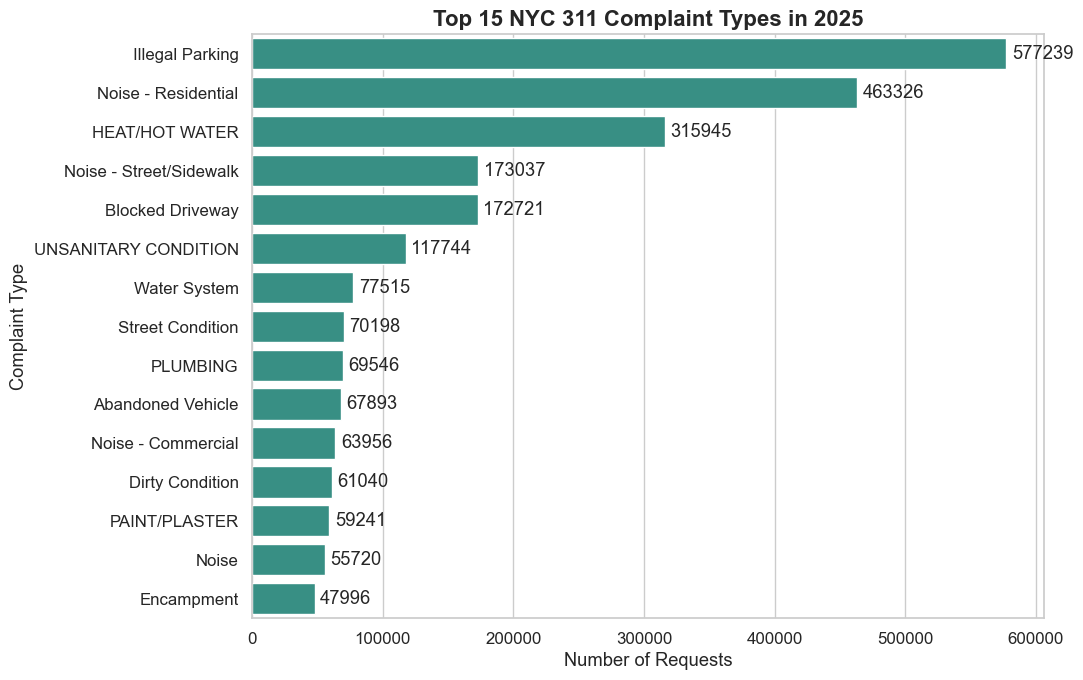

In [39]:
plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=top_complaints,
    y="complaint_type",
    x="count",
    color=MAIN_COLOR
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.title("Top 15 NYC 311 Complaint Types in 2025", fontsize=16, weight="bold")
plt.xlabel("Number of Requests")
plt.ylabel("Complaint Type")

plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

In [40]:
# Question 2: Which boroughs have the highest average resolution time?
pipeline = [
    {"$match": {
        "resolution_hours": {"$gte": 0, "$lte": 720},
        "borough": {"$ne": None}
    }},
    {"$group": {
        "_id": "$borough",
        "count": {"$sum": 1},
        "avg_resolution_hours": {"$avg": "$resolution_hours"}
    }},
    {"$sort": {"avg_resolution_hours": -1}}
]

borough_resolution = aggregate_to_df(pipeline).rename(columns={"_id": "borough"})
save_result(borough_resolution, "average_resolution_time_by_borough")
borough_resolution

Saved query_outputs\average_resolution_time_by_borough.csv


,borough,count,avg_resolution_hours
0,STATEN ISLAND,123313,57.372944
1,BRONX,781095,56.668531
2,MANHATTAN,640701,55.813474
3,BROOKLYN,993370,54.841426
4,QUEENS,797656,38.400496


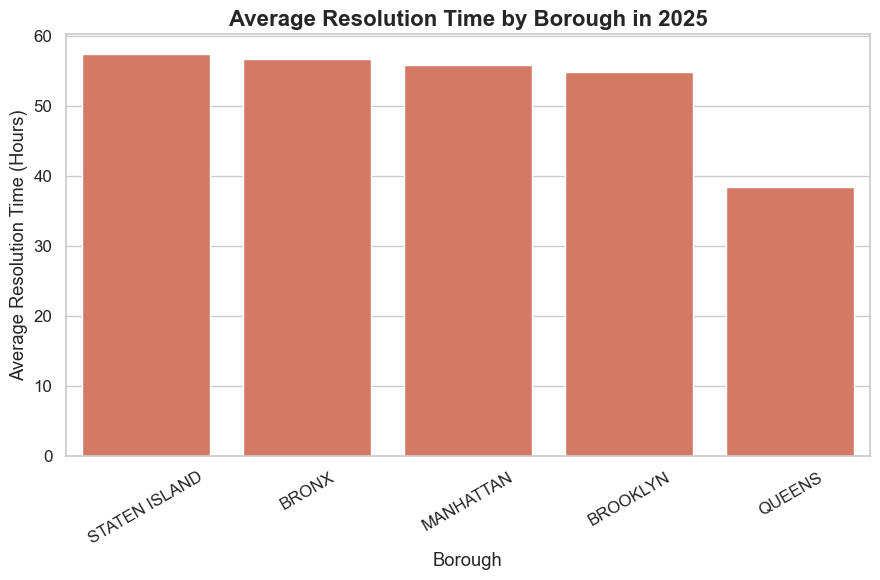

In [41]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=borough_resolution,
    x="borough",
    y="avg_resolution_hours",
    color=SECOND_COLOR
)

plt.title("Average Resolution Time by Borough in 2025", fontsize=16, weight="bold")
plt.xlabel("Borough")
plt.ylabel("Average Resolution Time (Hours)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [44]:
# Question 3: Do 311 requests show monthly or seasonal patterns?
pipeline = [
    {"$match": {"created_dt": {"$ne": None}}},
    {"$group": {
        "_id": {"year": {"$year": "$created_dt"}, "month": {"$month": "$created_dt"}},
        "count": {"$sum": 1}
    }},
    {"$sort": {"_id.year": 1, "_id.month": 1}}
]

monthly_trend = aggregate_to_df(pipeline)
monthly_trend["year"] = monthly_trend["_id"].apply(lambda x: x["year"])
monthly_trend["month"] = monthly_trend["_id"].apply(lambda x: x["month"])
monthly_trend["date"] = pd.to_datetime(monthly_trend["year"].astype(str) + "-" + monthly_trend["month"].astype(str) + "-01")
monthly_trend = monthly_trend.drop(columns=["_id"])
save_result(monthly_trend, "monthly_complaint_trend")
monthly_trend

Saved query_outputs\monthly_complaint_trend.csv


,count,year,month,date
0,348003,2025,1,2025-01-01
1,255189,2025,2,2025-02-01
2,281015,2025,3,2025-03-01
3,272332,2025,4,2025-04-01
4,294823,2025,5,2025-05-01
5,306165,2025,6,2025-06-01
6,315610,2025,7,2025-07-01
7,303833,2025,8,2025-08-01
8,302467,2025,9,2025-09-01
9,336390,2025,10,2025-10-01


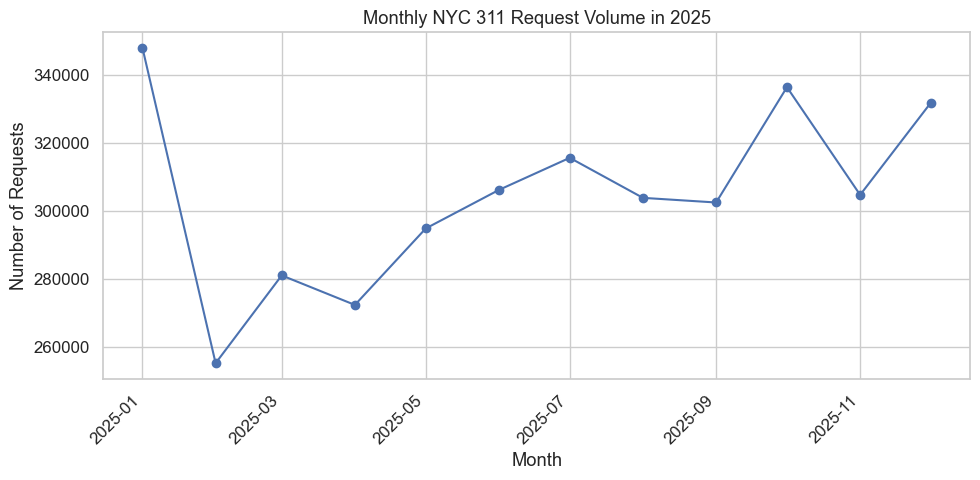

In [45]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_trend["date"], monthly_trend["count"], marker="o")
plt.title("Monthly NYC 311 Request Volume in 2025")
plt.xlabel("Month")
plt.ylabel("Number of Requests")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [47]:
# Question 4: Which boroughs generate the most 311 requests?
pipeline = [
    {
        "$match": {
            "borough": {
                "$exists": True,
                "$ne": None,
                "$ne": "Unspecified"
            }
        }
    },
    {
        "$group": {
            "_id": "$borough",
            "count": {"$sum": 1}
        }
    },
    {
        "$sort": {
            "count": -1
        }
    }
]

borough_counts = aggregate_to_df(pipeline).rename(columns={"_id": "borough"})

save_result(borough_counts, "borough_request_counts")

borough_counts

Saved query_outputs\borough_request_counts.csv


,borough,count
0,BROOKLYN,1078340
1,QUEENS,878212
2,BRONX,836520
3,MANHATTAN,725036
4,STATEN ISLAND,134302


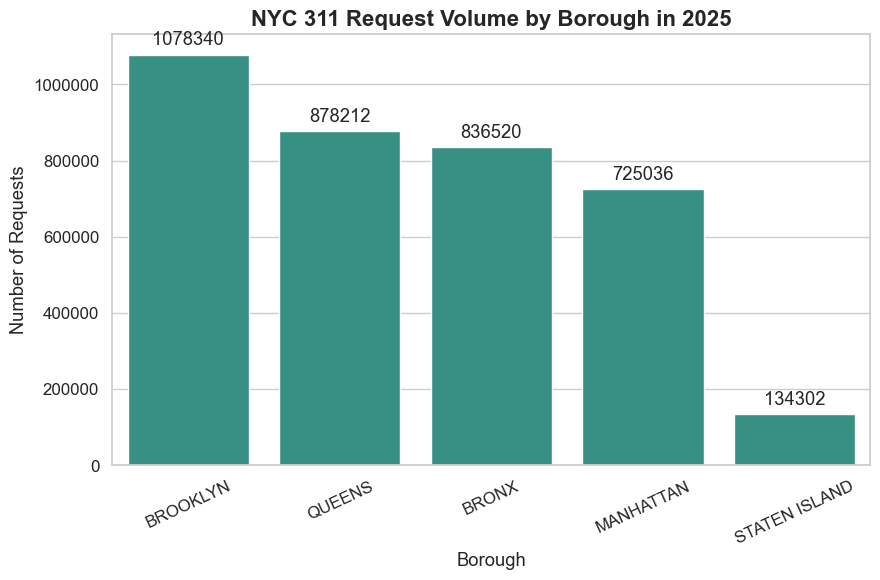

In [48]:
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=borough_counts,
    x="borough",
    y="count",
    color=MAIN_COLOR
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.title("NYC 311 Request Volume by Borough in 2025", fontsize=16, weight="bold")
plt.xlabel("Borough")
plt.ylabel("Number of Requests")

plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [49]:
# Question 5: Which complaint types take the longest to resolve?
pipeline = [
    {
        "$match": {
            "complaint_type": {"$exists": True, "$ne": None, "$ne": ""},
            "resolution_hours": {"$exists": True, "$ne": None, "$gte": 0, "$lte": 720}
        }
    },
    {
        "$group": {
            "_id": "$complaint_type",
            "count": {"$sum": 1},
            "avg_resolution_hours": {"$avg": "$resolution_hours"}
        }
    },
    {
        "$match": {
            "count": {"$gte": 500}
        }
    },
    {
        "$sort": {
            "avg_resolution_hours": -1
        }
    },
    {
        "$limit": 15
    }
]

slowest_complaints = aggregate_to_df(pipeline).rename(columns={"_id": "complaint_type"})

save_result(slowest_complaints, "slowest_complaint_types")

slowest_complaints

Saved query_outputs\slowest_complaint_types.csv


,complaint_type,count,avg_resolution_hours
0,For Hire Vehicle Complaint,2988,541.615686
1,Smoking or Vaping,915,381.556032
2,Food Establishment,684,346.837036
3,Curb Condition,6481,314.472965
4,Root/Sewer/Sidewalk Condition,2055,305.232144
5,OUTSIDE BUILDING,640,264.180421
6,ELEVATOR,1117,263.937552
7,APPLIANCE,15961,252.235994
8,GENERAL,23890,239.428444
9,Special Projects Inspection Team (SPIT),2208,237.967505


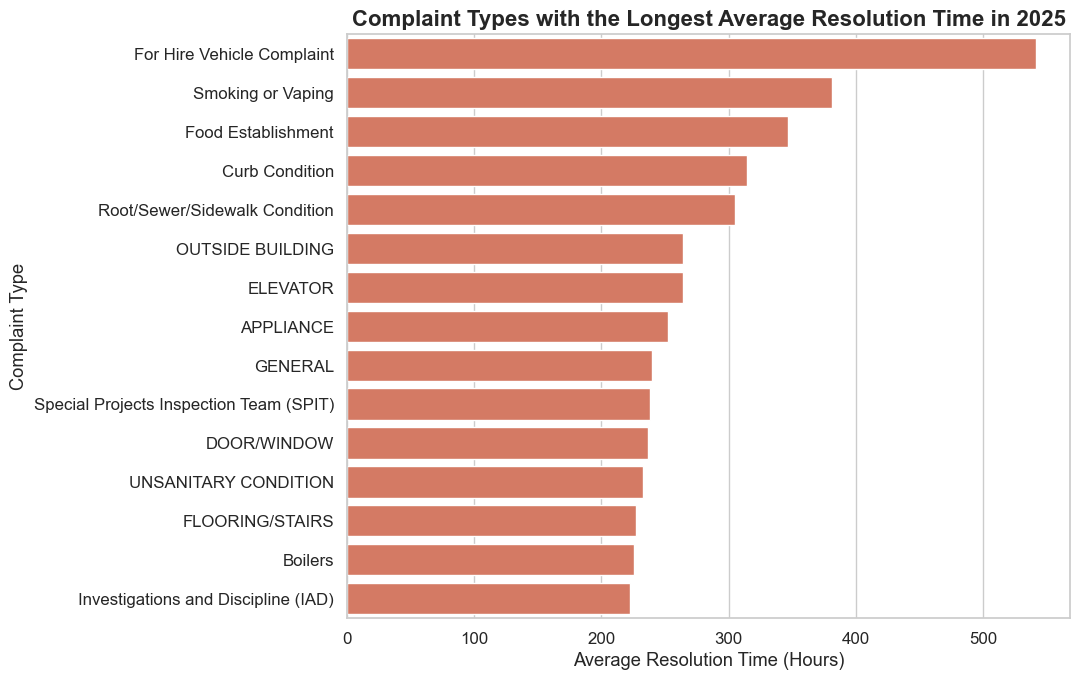

In [50]:
plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=slowest_complaints,
    y="complaint_type",
    x="avg_resolution_hours",
    color=SECOND_COLOR
)

plt.title("Complaint Types with the Longest Average Resolution Time in 2025", fontsize=16, weight="bold")
plt.xlabel("Average Resolution Time (Hours)")
plt.ylabel("Complaint Type")

plt.tight_layout()
plt.show()

In [56]:
# Heatmap of 311 request distribution
pipeline = [
    {
        "$match": {
            "lat": {"$gte": 40.45, "$lte": 40.95},
            "lon": {"$gte": -74.30, "$lte": -73.65}
        }
    },
    {
        "$sample": {"size": 60000}
    },
    {
        "$project": {
            "_id": 0,
            "lat": 1,
            "lon": 1,
            "borough": 1,
            "complaint_type": 1
        }
    }
]
map_df = pd.DataFrame(list(collection.aggregate(pipeline)))
map_df = map_df.dropna(subset=["lat", "lon"])

In [57]:
nyc_center = [40.7128, -74.0060]

m = folium.Map(
    location=nyc_center,
    zoom_start=11,
    tiles="cartodbpositron"
)

heat_data = map_df[["lat", "lon"]].values.tolist()

HeatMap(
    heat_data,
    radius=4,
    blur=5,
    min_opacity=0.25,
    max_zoom=13
).add_to(m)

m